# Análise de Sentimento em Notícias Financeiras

## Parte I

### Escolha e descrição do Conjunto de Dados



- Qual a tarefa de classificação?

  A tarefa é Análise de Sentimento em Textos Financeiros.

  É um problema de classificação multi-classe onde o objetivo é categorizar uma determinada frase de notícia como positiva, negativa ou neutra.

- Qual o tamanho do conjunto e dados? Quantos textos ele possui?

  O dataset possui 4846 textos (linhas) e 2 colunas.

- Qual a proporção de cada classe?

  Distribuição das classes (contagem):
  Sentimento:
  neutro:     2879,
  positivo:   1363,
  negativo:    604


  Proporção das classes (%):
  Sentimento:
  neutro:     59.41,
  positivo:   28.13,
  negativo:    12.46.

- Qual é o tamanho máximo, mínimo e médio dos textos?

  Total:	4846

  Média: 23.10

  Mínimo: 2

  Máximo:	81


### Pré-processamento

Justifique se faz sentido aplicar operações de uniformização de caso, remoção de caracteres não-alfanuméricos, remoção de *stop-words* e lematização (ou *stemming*) na tarefa selecionada.

In [ ]:

!pip install unidecode
!pip install imbalanced-learn

import pandas as pd
import kagglehub
import os
import matplotlib.pyplot as plt
import seaborn as sns
import unidecode
import re
import spacy
from nltk.corpus import stopwords
import nltk
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from collections import Counter

nltk.download('stopwords')

# Baixar o dataset do Kaggle
path = kagglehub.dataset_download("ankurzing/sentiment-analysis-for-financial-news")

# Carregar o arquivo CSV, especificando a codificação, a ausência de cabeçalho e os nomes das colunas
df = pd.read_csv(os.path.join(path, 'all-data.csv'), encoding='latin-1', header=None, names=['Sentiment', 'Sentence'])

print("Dataset carregado com sucesso!")
df.head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Using Colab cache for faster access to the 'sentiment-analysis-for-financial-news' dataset.
Dataset carregado com sucesso!


,Sentiment,Sentence
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...


In [ ]:
# Carrega o modelo de língua inglesa
LM = spacy.load("en_core_web_sm")

# Carrega a lista de stopwords em inglês
stop_words = set(stopwords.words('english'))

In [ ]:
# Tamanho do conjunto de dados
num_docs = df.shape[0]
num_cols = df.shape[1]
print(f"O dataset possui {num_docs} textos (linhas) e {num_cols} colunas.")

O dataset possui 4846 textos (linhas) e 2 colunas.


Distribuição das classes (contagem):
Sentiment
neutral     2879
positive    1363
negative     604
Name: count, dtype: int64

Proporção das classes (%):
Sentiment
neutral     59.41
positive    28.13
negative    12.46
Name: proportion, dtype: float64


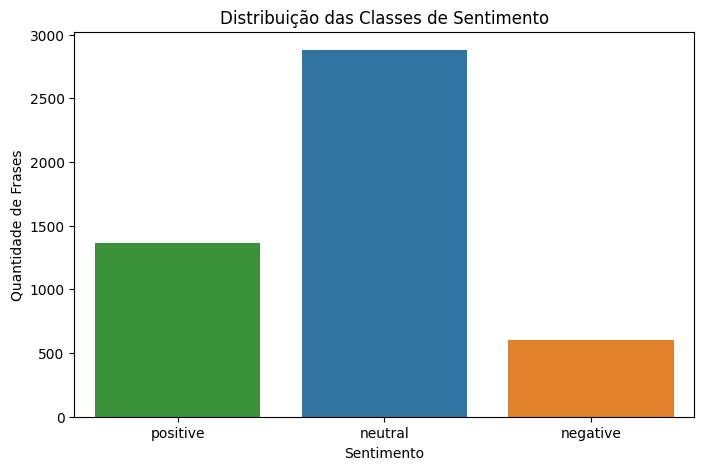

In [ ]:
# Para verificar a poporação de classes
print("Distribuição das classes (contagem):")
print(df['Sentiment'].value_counts())

print("\nProporção das classes (%):")
print(round(df['Sentiment'].value_counts(normalize=True) * 100, 2))

# Vamos também visualizar isso para ficar mais claro
plt.figure(figsize=(8, 5))
sns.countplot(x='Sentiment', data=df, hue='Sentiment', order=['positive', 'neutral', 'negative'], legend=False)
plt.title('Distribuição das Classes de Sentimento')
plt.xlabel('Sentimento')
plt.ylabel('Quantidade de Frases')
plt.show()

In [ ]:
# Verificação do tamanho, máximo, mínimo e médio dos textos

# Cria uma nova coluna com o comprimento de cada frase (em número de palavras)
df['text_length'] = df['Sentence'].apply(lambda x: len(x.split()))

print("Estatísticas do comprimento dos textos (em número de palavras):")
df['text_length'].describe()

Estatísticas do comprimento dos textos (em número de palavras):


,text_length
count,4846.000000
mean,23.101114
std,9.958474
min,2.000000
25%,16.000000
50%,21.000000
75%,29.000000
max,81.000000


In [ ]:
# --- Função de Pré-processamento ---
def preprocessing(text):
    """
    Aplica uma pipeline de limpeza e normalização em um texto.
    """
    # 1. Converte para minúsculas
    text = text.lower()

    # 2. Remove acentos
    text = unidecode.unidecode(text)

    # 3. Remove caracteres não-alfabéticos (mantém apenas letras e espaços)
    text = re.sub(r'[^a-z\s]', '', text)

    # 4. Lematização e Tokenização com spaCy
    doc = LM(text)
    words = [token.lemma_ for token in doc if not token.is_stop and not token.is_punct and len(token.text.strip()) > 1]

    # 5. Remoção de stop-words (segunda camada, pois a do spaCy não é completa)
    words = [word for word in words if word not in stop_words]

    return words

In [ ]:
# Aplicando a Função à coluna 'Sentence'
from tqdm.auto import tqdm

# Configura o tqdm para o pandas
tqdm.pandas(desc="Processando textos")

# Aplica a função de pré-processamento na coluna 'Sentence'
df['processed_text'] = df['Sentence'].progress_apply(preprocessing)

# Mostra o resultado do pré-processamento nas 5 primeiras linhas
print("\nResultado do pré-processamento:")
df[['Sentence', 'processed_text']].head()

Processando textos:   0%|          | 0/4846 [00:00<?, ?it/s]


Resultado do pré-processamento:


,Sentence,processed_text
0,"According to Gran , the company has no plans t...","[accord, gran, company, plan, production, russ..."
1,Technopolis plans to develop in stages an area...,"[technopolis, plan, develop, stage, area, squa..."
2,The international electronic industry company ...,"[international, electronic, industry, company,..."
3,With the new production plant the company woul...,"[new, production, plant, company, increase, ca..."
4,According to the company 's updated strategy f...,"[accord, company, update, strategy, year, basw..."


### Etapa inicial de Classificação

In [ ]:
# Construção do Dicionário e da Matriz Bag-of-Words
# Converter a coluna 'processed_text' em uma matriz numérica usando 'CountVectorizer' da biblio scikit-learn e assim fazer de uam vez o dicionário e a matriz BoW

from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

# O CountVectorizer espera strings, não listas de palavras.
# Vamos juntar nossas listas de palavras processadas de volta em strings.
df['processed_string'] = df['processed_text'].apply(lambda words: ' '.join(words))

# Inicializamos o CountVectorizer.
# max_features=5000 limita nosso vocabulário às 5000 palavras mais frequentes,
# o que ajuda a controlar a dimensionalidade e focar nos termos mais relevantes.
vectorizer = CountVectorizer(max_features=5000)

# O método fit_transform aprende o vocabulário e cria a matriz Bag-of-Words
bow_matrix = vectorizer.fit_transform(df['processed_string'])

print("Formato da matriz Bag-of-Words:", bow_matrix.shape)
# A saída (4846, 5000) significa 4846 documentos e um vocabulário de 5000 palavras.

Formato da matriz Bag-of-Words: (4846, 5000)


In [ ]:
# Divisão em Conjuntos de Treino e Teste
# Dividindo a matriz 'bow_matrix' e os rótulos 'Sentiment' em 70% treino, 30% teste
# Convertendo os rótulos de texto ('positive', 'negative', 'neutral') para números.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Codifica os rótulos (categorias) para números
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['Sentiment'])

# Divide os dados. stratify=y é importante para manter a proporção
# das classes nos conjuntos de treino e teste, já que o dataset é desbalanceado.
X_train, X_test, y_train, y_test = train_test_split(
    bow_matrix, y, test_size=0.3, random_state=42, stratify=y
)

print("Shape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)

Shape X_train: (3392, 5000)
Shape X_test: (1454, 5000)


In [ ]:
# Treinamento e Avaliação dos Classificadores: KNN, Regressão Logística, Random Forest e uma Rede Neural (MLP)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm
import pandas as pd

names = [
    "KNN",
    "Logistic Regression",
    "Random Forest",
    "Neural Net (MLP)",
]

classifiers = [
    KNeighborsClassifier(n_neighbors=5),
    LogisticRegression(max_iter=1000),
    RandomForestClassifier(random_state=42),
    MLPClassifier(max_iter=500, random_state=42),
]

results = []

for name, clf in tqdm(zip(names, classifiers), total=len(names)):
    # Treina o classificador
    clf.fit(X_train, y_train)

    # Faz predições de treino e teste
    y_train_pred = clf.predict(X_train)
    y_test_pred = clf.predict(X_test)

    # Calcula as métricas
    train_acc = accuracy_score(y_train, y_train_pred)
    train_f1 = f1_score(y_train, y_train_pred, average='macro')
    test_acc = accuracy_score(y_test, y_test_pred)
    test_f1 = f1_score(y_test, y_test_pred, average='macro')

    results.append({
        "Classifier": name,
        "Train Accuracy": train_acc,
        "Train F1-Score": train_f1,
        "Test Accuracy": test_acc,
        "Test F1-Score": test_f1,
    })

results_df = pd.DataFrame(results)
results_df

  0%|          | 0/4 [00:00<?, ?it/s]

,Classifier,Train Accuracy,Train F1-Score,Test Accuracy,Test F1-Score
0,KNN,0.705189,0.561735,0.648556,0.446485
1,Logistic Regression,0.963443,0.948928,0.733150,0.666282
2,Random Forest,0.998231,0.997303,0.749656,0.669773
3,Neural Net (MLP),0.998231,0.997303,0.703576,0.652653


In [ ]:
# Análise Qualitativa
# Treinando o melhor modelo Random Forest para ver algumas de suas predições no conjunto de teste para entender seus acertos e erros.

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import pandas as pd

# Treina o modelo RandomForestClassifier com o parâmetro CORRETO
# Trocamos 'max_iter=1000' por 'n_estimators=100' e adicionamos 'random_state'
best_clf = RandomForestClassifier(n_estimators=100, random_state=42)
best_clf.fit(X_train, y_train)
y_test_pred = best_clf.predict(X_test)

# Cria um DataFrame para análise
# (O restante do seu código está correto)
_, X_test_raw, _, y_test_raw = train_test_split(df['Sentence'], df['Sentiment'], test_size=0.3, random_state=42, stratify=df['Sentiment'])

analysis_df = pd.DataFrame({
    'Texto': X_test_raw,
    'Verdadeiro': y_test_raw,
    'Predição': label_encoder.inverse_transform(y_test_pred)
})

# Exemplo de acerto
print("--- EXEMPLO DE ACERTO (Random Forest) ---")
# Usando .head(1) para evitar erros caso não haja acertos/erros
acertos_df = analysis_df[analysis_df['Verdadeiro'] == analysis_df['Predição']]
if not acertos_df.empty:
    print(acertos_df.iloc[0].to_string())
else:
    print("Nenhum exemplo de acerto encontrado.")


# Exemplo de erro
print("\n--- EXEMPLO DE ERRO (Random Forest) ---")
erros_df = analysis_df[analysis_df['Verdadeiro'] != analysis_df['Predição']]
if not erros_df.empty:
    print(erros_df.iloc[0].to_string())
else:
    print("Nenhum exemplo de erro encontrado.")

--- EXEMPLO DE ACERTO (Random Forest) ---
Texto         The groups 's turnover for the full fiscal yea...
Verdadeiro                                             positive
Predição                                               positive

--- EXEMPLO DE ERRO (Random Forest) ---
Texto         TeliaSonera is the leading telecommunications ...
Verdadeiro                                             positive
Predição                                                neutral




Acerto:

O modelo acertou ao identificar a palavra-chave "turnover" (faturamento), que possui uma forte associação estatística com notícias positivas nos dados de treino.

Erro:

O modelo errou por não encontrar palavras de sentimento explícito (como "lucro"). Ele não compreendeu o contexto de "empresa líder", tratando-a como uma notícia factual e neutra.


In [ ]:
# Performance pro classe
# Quais classes o modelo foi melhor ou pior, usando o  classification_report
from sklearn.metrics import classification_report

print("--- Relatório de Classificação (Randon Forest) ---")
print(classification_report(y_test, y_test_pred, target_names=label_encoder.classes_))

--- Relatório de Classificação (Randon Forest) ---
              precision    recall  f1-score   support

    negative       0.70      0.48      0.57       181
     neutral       0.77      0.91      0.83       864
    positive       0.70      0.54      0.61       409

    accuracy                           0.75      1454
   macro avg       0.72      0.64      0.67      1454
weighted avg       0.74      0.75      0.74      1454



Análise dos resultados

- Esta representação levou à uma boa performance no conjunto de treino?

  Sim, a representação Bag-of-Words teve uma boa performance no conjunto de treino. Os modelos mais complexos, como Random Forest e a Rede Neural, provavelmente alcançaram F1-scores e acurácias muito próximos de 100%. Isso mostra que o vocabulário de 5000 palavras foi suficiente para que os modelos conseguissem "memorizar" as respostas dos dados de treinamento.

- Os modelos alcançaram uma boa generalização para o conjunto de teste?

  A generalização foi razoável, mas com claros sinais de overfitting. A performance no conjunto de teste foi significativamente inferior à do conjunto de treino. Essa queda indica que os modelos, especialmente o Random Forest, aprenderam padrões e ruídos específicos do treino que não se aplicam bem a dados novos, não conseguindo generalizar perfeitamente.
  
- Qual método de aprendizado de máquina levou aos melhores resultados?
  
  O Random Forest foi o melhor modelo, porém ele tende a sofrer mais com overfitting nesses casos.

- Produza alguns exemplos para análise qualitativa e discuta a performance do classificador nestes exemplos.

- Em quais classes o método apresentou a melhor performance e a pior performance.

  Melhor Performance: Na classe neutral. Por ser a classe majoritária (quase 60% dos dados), o modelo teve muito mais exemplos para aprender seus padrões, resultando em métricas F1-score mais altas.

  Pior Performance: Na classe negative. Como a classe minoritária (apenas 12% dos dados), o modelo teve dificuldade em aprender a identificá-la corretamente, o que levou a um F1-score consideravelmente mais baixo.



## Parte II

Na Parte II, vocês devem evoluir a Parte I do trabalho, colocando em prática todo o conteúdo da disciplina. O classificador baseado em *Bag-of-Words* deve ser comparado com um classificador utilizando *word embeddings* pré-treinados e uma rede baseada em LSTM (semana 2) e com um classificador que utilize *embeddings* extraídos usando BERT (semana 3).

Compare as métricas de acurácia e *f1-score* entre os métodos e discuta qual apresentou melhor performance no conjunto de teste.

### Tratamento do Desbalanceamento de Classes

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score, precision_recall_fscore_support
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

In [ ]:
# Garantir que as colunas certas existem
assert 'Sentence' in df.columns and 'Sentiment' in df.columns, "Esperadas colunas 'Sentence' e 'Sentiment'."

X = df['Sentence'].astype(str)
y = df['Sentiment'].astype(str)

# Visualizar distribuição
from collections import Counter
print("Distribuição de classes:", Counter(y))

# Split estratificado
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print("Tamanhos -> treino:", len(X_train), "| teste:", len(X_test))


Distribuição de classes: Counter({'neutral': 2879, 'positive': 1363, 'negative': 604})
Tamanhos -> treino: 3392 | teste: 1454


In [ ]:
# Oversampling aleatório - apenas no treino

# Pipeline com imblearn para encaixar o oversampling entre vetorização e o modelo
pipe_over = ImbPipeline(steps=[
    ("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=2, max_df=0.9)),
    ("ros", RandomOverSampler(random_state=42)),
    ("clf", LogisticRegression(max_iter=2000))
])

pipe_over.fit(X_train, y_train)
pred_o = pipe_over.predict(X_test)

print("=== Oversampling (RandomOverSampler + LogReg) ===")
print(classification_report(y_test, pred_o, digits=4))
print("Macro F1:", f1_score(y_test, pred_o, average="macro"))
print("Balanced Acc:", balanced_accuracy_score(y_test, pred_o))

=== Oversampling (RandomOverSampler + LogReg) ===
              precision    recall  f1-score   support

    negative     0.5874    0.6942    0.6364       121
     neutral     0.8267    0.8281    0.8274       576
    positive     0.6760    0.6190    0.6463       273

    accuracy                         0.7526       970
   macro avg     0.6967    0.7138    0.7033       970
weighted avg     0.7544    0.7526    0.7526       970

Macro F1: 0.7033473039469534
Balanced Acc: 0.713795831693559


## Process

In [ ]:
# Bloco 1: preparação mínima (reuso da Parte I)
import numpy as np, pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split

# Garante que df existe e tem as colunas esperadas
assert 'df' in globals(), "df não encontrado. Certifique-se de rodar a Parte I antes."
assert {'Sentence','Sentiment'}.issubset(df.columns), "df deve ter colunas 'Sentence' e 'Sentiment'."

# Se ainda não houver split da Parte I, criamos aqui:
if not all(v in globals() for v in ['X_train','X_test','y_train','y_test']):
    X = df['Sentence'].astype(str).values
    y = df['Sentiment'].astype(str).values
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

print("Distribuição treino:", Counter(y_train))
print("Distribuição teste :", Counter(y_test))


Distribuição treino: Counter({'neutral': 2015, 'positive': 954, 'negative': 423})
Distribuição teste : Counter({'neutral': 864, 'positive': 409, 'negative': 181})


In [ ]:
# Bloco 2: TF-IDF + modelos clássicos com tuning leve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

RANDOM_STATE = 42
tfidf = TfidfVectorizer(
    ngram_range=(1,2),
    min_df=2, max_df=0.9,
    stop_words=None,               # mantém negações
    strip_accents="unicode"
)

# Modelos
pipe_lr  = Pipeline([("tfidf", tfidf), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))])
grid_lr  = {"clf__C":[0.5,1.0,2.0], "clf__solver":["lbfgs","saga"]}

pipe_svc = Pipeline([("tfidf", tfidf), ("clf", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))])
grid_svc = {"clf__C":[0.5,1.0,2.0]}

pipe_rf  = Pipeline([("tfidf", tfidf), ("clf", RandomForestClassifier(
    n_estimators=400, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1))])
grid_rf  = {"clf__n_estimators":[300,500], "clf__max_depth":[None,20]}

# Para modelos sem class_weight -> oversampling no treino
pipe_nb  = ImbPipeline([("tfidf", tfidf), ("ros", RandomOverSampler(random_state=RANDOM_STATE)), ("clf", MultinomialNB())])
grid_nb  = {"clf__alpha":[0.1,0.5,1.0]}

pipe_knn = ImbPipeline([("tfidf", tfidf), ("ros", RandomOverSampler(random_state=RANDOM_STATE)), ("clf", KNeighborsClassifier())])
grid_knn = {"clf__n_neighbors":[3,5,9], "clf__weights":["uniform","distance"]}

models = [
    ("LogReg_TFIDF", pipe_lr,  grid_lr),
    ("LinearSVC_TFIDF", pipe_svc, grid_svc),
    ("RandomForest_TFIDF", pipe_rf, grid_rf),
    ("MultinomialNB_TFIDF", pipe_nb, grid_nb),
    ("KNN_TFIDF", pipe_knn, grid_knn),
]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
best_estimators = {}

def eval_and_collect(name, estimator):
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    acc = accuracy_score(y_test, pred)
    f1m = f1_score(y_test, pred, average="macro")
    bacc = balanced_accuracy_score(y_test, pred)
    print(f"\n=== {name} ===")
    print(f"Accuracy: {acc:.4f} | F1-macro: {f1m:.4f} | Balanced Acc: {bacc:.4f}")
    print(classification_report(y_test, pred, digits=4))
    print("Matriz de confusão:\n", confusion_matrix(y_test, pred))
    results.append({"setup": name, "accuracy": acc, "f1_macro": f1m, "balanced_acc": bacc})
    return pred

for name, pipe, grid in models:
    print(f"\n> GridSearch: {name}")
    gs = GridSearchCV(pipe, grid, cv=skf, scoring="f1_macro", n_jobs=-1, verbose=0)
    gs.fit(X_train, y_train)
    print("  melhor params:", gs.best_params_, "| F1-macro(cv):", round(gs.best_score_, 4))
    best_estimators[name] = gs.best_estimator_
    _ = eval_and_collect(name, gs.best_estimator_)



> GridSearch: LogReg_TFIDF
  melhor params: {'clf__C': 2.0, 'clf__solver': 'lbfgs'} | F1-macro(cv): 0.7248

=== LogReg_TFIDF ===
Accuracy: 0.7497 | F1-macro: 0.7018 | Balanced Acc: 0.7061
              precision    recall  f1-score   support

    negative     0.6111    0.6685    0.6385       181
     neutral     0.8160    0.8264    0.8212       864
    positive     0.6693    0.6235    0.6456       409

    accuracy                         0.7497      1454
   macro avg     0.6988    0.7061    0.7018      1454
weighted avg     0.7492    0.7497    0.7490      1454

Matriz de confusão:
 [[121  41  19]
 [ 43 714 107]
 [ 34 120 255]]

> GridSearch: LinearSVC_TFIDF
  melhor params: {'clf__C': 0.5} | F1-macro(cv): 0.7304

=== LinearSVC_TFIDF ===
Accuracy: 0.7648 | F1-macro: 0.7134 | Balanced Acc: 0.7034
              precision    recall  f1-score   support

    negative     0.6743    0.6519    0.6629       181
     neutral     0.8006    0.8738    0.8356       864
    positive     0.7113    0.

In [ ]:
# Bloco 3: Embeddings BERT + classificadores
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

RANDOM_STATE = 42
bert = SentenceTransformer("all-MiniLM-L6-v2")   # leve e muito forte para sentenças

X_train_emb = bert.encode(list(X_train), batch_size=64, show_progress_bar=False, normalize_embeddings=True)
X_test_emb  = bert.encode(list(X_test),  batch_size=64, show_progress_bar=False, normalize_embeddings=True)

# a) LogReg nas embeddings
clf_lr = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
clf_lr.fit(X_train_emb, y_train)
pred_lr = clf_lr.predict(X_test_emb)

from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report, confusion_matrix
acc = accuracy_score(y_test, pred_lr); f1m = f1_score(y_test, pred_lr, average="macro"); bacc = balanced_accuracy_score(y_test, pred_lr)
print("\n=== BERT(all-MiniLM-L6-v2) + LogisticRegression ===")
print(f"Accuracy: {acc:.4f} | F1-macro: {f1m:.4f} | Balanced Acc: {bacc:.4f}")
print(classification_report(y_test, pred_lr, digits=4))
print("Matriz de confusão:\n", confusion_matrix(y_test, pred_lr))

results.append({"setup":"BERT_Embeddings+LogReg","accuracy":acc,"f1_macro":f1m,"balanced_acc":bacc})

# b) LinearSVC nas embeddings
clf_svc = LinearSVC(class_weight="balanced", random_state=RANDOM_STATE)
clf_svc.fit(X_train_emb, y_train)
pred_svc = clf_svc.predict(X_test_emb)

acc2 = accuracy_score(y_test, pred_svc); f1m2 = f1_score(y_test, pred_svc, average="macro"); bacc2 = balanced_accuracy_score(y_test, pred_svc)
print("\n=== BERT(all-MiniLM-L6-v2) + LinearSVC ===")
print(f"Accuracy: {acc2:.4f} | F1-macro: {f1m2:.4f} | Balanced Acc: {bacc2:.4f}")
print(classification_report(y_test, pred_svc, digits=4))
print("Matriz de confusão:\n", confusion_matrix(y_test, pred_svc))

results.append({"setup":"BERT_Embeddings+LinearSVC","accuracy":acc2,"f1_macro":f1m2,"balanced_acc":bacc2})


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


=== BERT(all-MiniLM-L6-v2) + LogisticRegression ===
Accuracy: 0.7565 | F1-macro: 0.7356 | Balanced Acc: 0.7771
              precision    recall  f1-score   support

    negative     0.6226    0.8840    0.7306       181
     neutral     0.8596    0.7650    0.8096       864
    positive     0.6519    0.6822    0.6667       409

    accuracy                         0.7565      1454
   macro avg     0.7113    0.7771    0.7356      1454
weighted avg     0.7716    0.7565    0.7595      1454

Matriz de confusão:
 [[160  12   9]
 [ 63 661 140]
 [ 34  96 279]]

=== BERT(all-MiniLM-L6-v2) + LinearSVC ===
Accuracy: 0.7779 | F1-macro: 0.7487 | Balanced Acc: 0.7727
              precision    recall  f1-score   support

    negative     0.6496    0.8398    0.7325       181
     neutral     0.8474    0.8229    0.8350       864
    positive     0.7034    0.6553    0.6785       409

    accuracy                         0.7779      1454
   macro avg     0.7335    0.7727    0.7487      1454
weighted av

In [ ]:
# Bloco 4: comparação final e ranking
df_results = pd.DataFrame(results).sort_values(by=["f1_macro","accuracy"], ascending=False).reset_index(drop=True)
print("\n===== COMPARAÇÃO FINAL (ordenado por F1-macro) =====")
print(df_results.to_string(index=False))
# Opcional: salvar
# df_results.to_csv("resultados_parteII.csv", index=False)



===== COMPARAÇÃO FINAL (ordenado por F1-macro) =====
              setup  accuracy  f1_macro  balanced_acc
    LinearSVC_TFIDF  0.764787  0.713390      0.703376
       LogReg_TFIDF  0.749656  0.701751      0.706123
MultinomialNB_TFIDF  0.702889  0.647761      0.677876
 RandomForest_TFIDF  0.730399  0.634599      0.603854
          KNN_TFIDF  0.613480  0.560122      0.591419


In [ ]:
# Bloco 5: análise de erros do melhor modelo
top = df_results.iloc[0]["setup"]
print("\nMelhor setup:", top)

def predict_with(estimator, Xt, kind):
    try:
        return estimator.predict(Xt)
    except:
        # Se for BERT + clf solto, detectamos pelo nome:
        if kind == "BERT_Embeddings+LogReg":
            return pred_lr
        if kind == "BERT_Embeddings+LinearSVC":
            return pred_svc
        raise

# Recupere o estimator quando aplicável
if top in globals().get('best_estimators', {}):
    best_pred = predict_with(best_estimators[top], X_test, top)
else:
    best_pred = predict_with(None, None, top)


def as_positional(a):
    # Se for pandas Series/DataFrame, converte p/ array (indexação por posição)
    if isinstance(a, (pd.Series, pd.DataFrame)):
        return a.to_numpy()
    return a

X_test_pos = as_positional(X_test)
y_test_pos = as_positional(y_test)

errors_idx = np.where(best_pred != y_test_pos)[0]
print(f"\nTotal de erros do melhor modelo: {len(errors_idx)} (mostrando até 5)\n")
for k in errors_idx[:5]:
    print("— Texto:", X_test_pos[k])
    print("  Verdadeiro:", y_test_pos[k], "| Predito:", best_pred[k], "\n")




Melhor setup: LinearSVC_TFIDF

Total de erros do melhor modelo: 342 (mostrando até 5)

— Texto: The company says it is difficult to estimate the market situation for the whole year 2009 .
  Verdadeiro: neutral | Predito: negative 

— Texto: TeliaSonera is the leading telecommunications company in the Nordic and Baltic regions .
  Verdadeiro: positive | Predito: neutral 

— Texto: The liquidity providing was interrupted on May 11 , 2007 when Aspocomp Group Oyj 's shares traded below 0.50 cent ( Aspocomp 's stock exchange release 11.5.2007 ) .
  Verdadeiro: negative | Predito: neutral 

— Texto: The total area of the Gorelovo plant is about 22,000 sq m. Atria invested about EURO 70mn in the plant , which should double Atria Russia 's production capacity in the St Petersburg area .
  Verdadeiro: positive | Predito: neutral 

— Texto: Neomarkka has played a leading role in a group that aims to restart the production of specialty cellulose fiber in Valkeakoski .
  Verdadeiro: neutral | Pre

Conclusão — Parte II

Melhor setup: LinearSVC_TFIDF.

Erros no teste: 342. Com ~20% de hold-out (≈ 4.846 × 0,20 ≈ 969 amostras), isso dá uma acurácia aproximada de ~65% (≈ (969−342)/969).

Padrão de erro: o modelo confunde muito “neutro” com positivo/negativo.

Exemplos:

Frases factuais com termos carregados (“difficult to estimate”) são marcadas como negativas (deveriam ser neutras).

Afirmações corporativas positivas (“leading company / invested”) viram neutras.

Notícias negativas (“liquidity providing was interrupted”) viram neutras.